# Sector-Coupled Japan Model Analysis (2023 Weather Year)
This notebook analyzes the solved PyPSA-Earth sector-coupled network for Japan
(100 clusters, 168h resolution, 2023) and answers:
- General model statistics
- Heating technologies
- Heating components
- Installed heating capacities
- Heat pump electricity consumption
- Solar thermal generation
- Thermal storage operation
- Connections between heating components

In [19]:
import pypsa
import pandas
import matplotlib.pyplot as plt

network = pypsa.Network("resources/elec_s_100_ec_lv1_Co2L-168h_168h_2023_0.071.nc")

# Each snapshot represents several hours (168h, last one 24h); weights are needed for annual MWh
w = network.snapshot_weightings.generators
print("Snapshots:", len(network.snapshots), "| Total hours:", w.sum())

INFO:pypsa.io:Imported network elec_s_100_ec_lv1_Co2L-168h_168h_2023_0.071.nc has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, stores


Snapshots: 53 | Total hours: 8760.0


## 1. General model statistics

In [20]:
print(network)
print("Generators:", len(network.generators))
print("Links:", len(network.links))
print("Stores:", len(network.stores))
print("Storage Units:", len(network.storage_units))
print("Loads:", len(network.loads))
print("Buses:", len(network.buses))

display(network.buses.carrier.value_counts())
display(network.generators.carrier.value_counts())
display(network.links.carrier.value_counts())
display(network.stores.carrier.value_counts())

PyPSA Network
Components:
 - Bus: 3246
 - Carrier: 110
 - Generator: 4460
 - GlobalConstraint: 2
 - Line: 182
 - Link: 5315
 - Load: 4882
 - StorageUnit: 58
 - Store: 1338
Snapshots: 53
Generators: 4460
Links: 5315
Stores: 1338
Storage Units: 58
Loads: 4882
Buses: 3246


carrier
gas for industry                           1140
solid biomass for industry                  190
battery                                     100
AC                                           95
co2 stored                                   95
gas                                          95
oil                                          95
coal                                         95
biomass                                      95
H2                                           95
residential rural heat                       95
residential rural water tanks                95
services rural heat                          95
services rural water tanks                   95
residential urban decentral heat             95
residential urban decentral water tanks      95
services urban decentral heat                95
services urban decentral water tanks         95
urban central heat                           95
urban central water tanks                    95
biogas                          

carrier
load shedding                                3246
onwind                                         95
solar                                          95
gas                                            95
oil                                            95
coal                                           95
biomass                                        95
residential rural solar thermal                95
services rural solar thermal                   95
residential urban decentral solar thermal      95
services urban decentral solar thermal         95
urban central solar thermal                    95
offwind-ac                                     75
offwind-dc                                     75
ror                                             7
nuclear                                         6
geothermal                                      5
lignite                                         1
Name: count, dtype: int64

carrier
gas for industry                                      1140
solid biomass transport                                364
solid biomass for industry                             190
CO2 pipeline                                           182
battery charger                                        100
battery discharger                                     100
co2 vent                                                95
H2 Electrolysis                                         95
SMR                                                     95
SMR CC                                                  95
H2 Fuel Cell                                            95
residential rural ground heat pump                      95
residential rural water tanks charger                   95
residential rural water tanks discharger                95
residential rural resistive heater                      95
residential rural gas boiler                            95
services rural ground heat pump                 

carrier
battery                                    100
co2 stored                                  95
gas                                         95
oil                                         95
coal                                        95
biomass                                     95
H2 Store Tank                               95
residential rural water tanks               95
services rural water tanks                  95
residential urban decentral water tanks     95
services urban decentral water tanks        95
urban central water tanks                   95
biogas                                      95
solid biomass                               95
co2                                          1
lignite                                      1
H2                                           1
Name: count, dtype: int64

## 2. Heating technologies (Links)

In [21]:
heating_links = network.links[
    network.links.carrier.str.contains(
        "heat|heater|pump|boiler|thermal|water|tank|pit|CHP", case=False, na=False
    )
]
display(
    heating_links[
        ["carrier", "bus0", "bus1", "bus2", "p_nom_opt", "efficiency"]
    ].sort_values("carrier")
)

,carrier,bus0,bus1,bus2,p_nom_opt,efficiency
Link,,,,,,
JP8 0 residential rural gas boiler,residential rural gas boiler,JP8 0 gas,JP8 0 residential rural heat,co2 atmosphere,3.321007,0.97
JP0 32 residential rural gas boiler,residential rural gas boiler,JP0 32 gas,JP0 32 residential rural heat,co2 atmosphere,0.400891,0.97
JP0 33 residential rural gas boiler,residential rural gas boiler,JP0 33 gas,JP0 33 residential rural heat,co2 atmosphere,0.000818,0.97
JP0 34 residential rural gas boiler,residential rural gas boiler,JP0 34 gas,JP0 34 residential rural heat,co2 atmosphere,0.000057,0.97
JP0 35 residential rural gas boiler,residential rural gas boiler,JP0 35 gas,JP0 35 residential rural heat,co2 atmosphere,0.184602,0.97
...,...,...,...,...,...,...
JP0 7 urban central water tanks discharger,urban central water tanks discharger,JP0 7 urban central water tanks,JP0 7 urban central heat,,1.569612,0.90
JP0 70 urban central water tanks discharger,urban central water tanks discharger,JP0 70 urban central water tanks,JP0 70 urban central heat,,3.007027,0.90
JP0 71 urban central water tanks discharger,urban central water tanks discharger,JP0 71 urban central water tanks,JP0 71 urban central heat,,2.484212,0.90


## 3. Installed heating capacities

carrier
urban central gas boiler                              14263.738946
residential urban decentral gas boiler                 1128.721312
services urban decentral gas boiler                     332.704083
residential urban decentral resistive heater            308.288525
urban central water tanks charger                       203.469263
urban central water tanks discharger                    183.122298
services urban decentral resistive heater                90.398196
urban central resistive heater                           77.814927
residential urban decentral water tanks charger          68.260255
residential rural gas boiler                             63.803166
residential urban decentral water tanks discharger       61.434227
residential rural resistive heater                       60.338569
urban central air heat pump                              48.639054
residential urban decentral air heat pump                37.628430
services urban decentral water tanks charger          

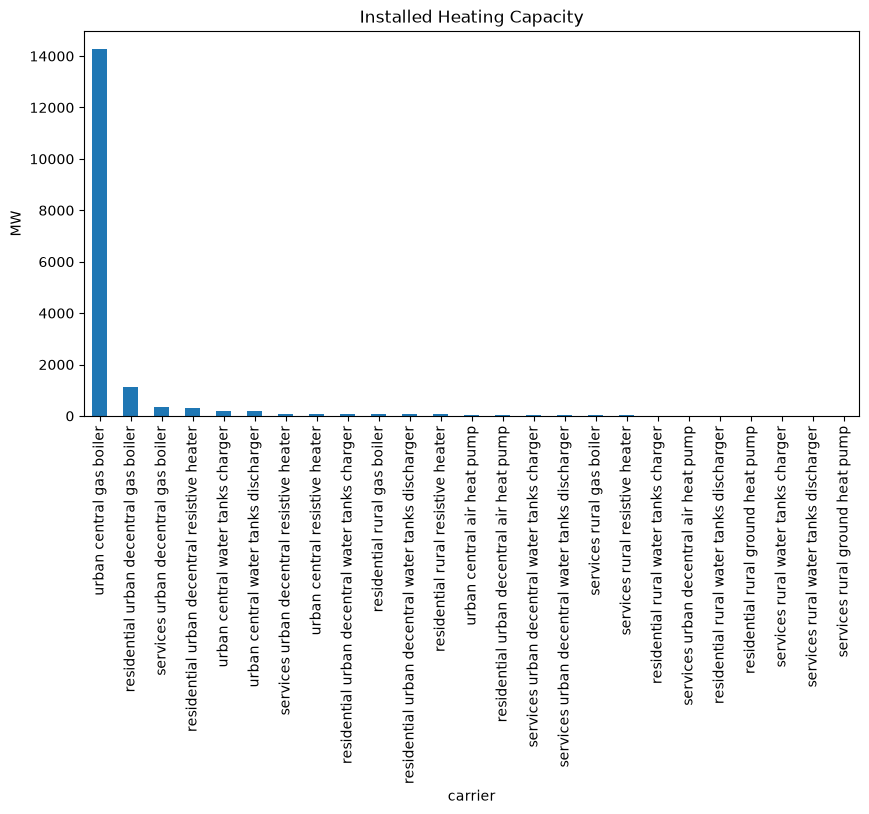

In [22]:
heating_capacity = (
    heating_links.groupby("carrier").p_nom_opt.sum().sort_values(ascending=False)
)
display(heating_capacity)

heating_capacity.plot.bar(figsize=(10, 5))
plt.ylabel("MW")
plt.title("Installed Heating Capacity")
plt.show()

## 4. Heat pump analysis
Note: the static `efficiency` column shows 1.0 for heat pumps; the real time-varying COP
is stored in `network.links_t.efficiency`.

In [23]:
heat_pumps = network.links[
    network.links.carrier.str.contains("heat pump", case=False, na=False)
]
display(heat_pumps[["carrier", "p_nom_opt", "efficiency", "bus0", "bus1"]])

print("Total installed heat pump capacity (MW):")
print(heat_pumps.p_nom_opt.sum())

,carrier,p_nom_opt,efficiency,bus0,bus1
Link,,,,,
JP0 0 residential rural ground heat pump,residential rural ground heat pump,0.048230,1.0,JP0 0 low voltage,JP0 0 residential rural heat
JP0 1 residential rural ground heat pump,residential rural ground heat pump,0.000006,1.0,JP0 1 low voltage,JP0 1 residential rural heat
JP0 10 residential rural ground heat pump,residential rural ground heat pump,0.000006,1.0,JP0 10 low voltage,JP0 10 residential rural heat
JP0 11 residential rural ground heat pump,residential rural ground heat pump,0.006628,1.0,JP0 11 low voltage,JP0 11 residential rural heat
JP0 12 residential rural ground heat pump,residential rural ground heat pump,0.000006,1.0,JP0 12 low voltage,JP0 12 residential rural heat
...,...,...,...,...,...
JP0 90 urban central air heat pump,urban central air heat pump,0.000046,1.0,JP0 90 low voltage,JP0 90 urban central heat
JP2 0 urban central air heat pump,urban central air heat pump,0.001902,1.0,JP2 0 low voltage,JP2 0 urban central heat
JP5 0 urban central air heat pump,urban central air heat pump,0.339200,1.0,JP5 0 low voltage,JP5 0 urban central heat


Total installed heat pump capacity (MW):
111.23569256474029


### Heat pump electricity consumption

Annual electricity consumption (MWh)
753903.2190396753


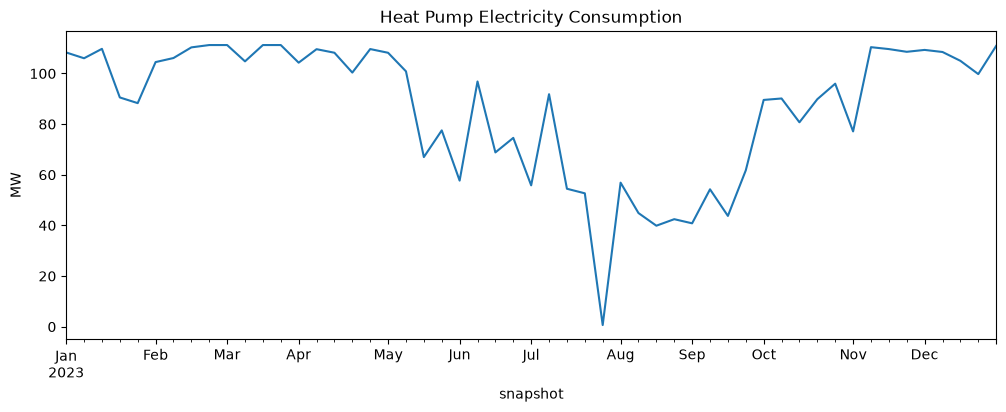

In [24]:
heat_pump_power = network.links_t.p0[heat_pumps.index]

print("Annual electricity consumption (MWh)")
print(heat_pump_power.mul(w, axis=0).sum().sum())

heat_pump_power.sum(axis=1).plot(figsize=(12, 4))
plt.ylabel("MW")
plt.title("Heat Pump Electricity Consumption")
plt.show()

### Heat supplied by heat pumps

In [25]:
heat_output = -network.links_t.p1[heat_pumps.index]
print("Annual heat supplied (MWh)")
print(heat_output.mul(w, axis=0).sum().sum())

Annual heat supplied (MWh)
2274465.6434119274


## 5. Solar thermal

In [26]:
solar_thermal = network.generators[
    network.generators.carrier.str.contains("solar thermal", case=False, na=False)
]
display(solar_thermal[["carrier", "bus", "p_nom_opt"]])

print("Installed solar thermal (MW):", solar_thermal.p_nom_opt.sum())
print(
    "Annual solar thermal heat (MWh):",
    network.generators_t.p[solar_thermal.index].mul(w, axis=0).sum().sum(),
)

,carrier,bus,p_nom_opt
Generator,,,
JP0 0 residential rural solar thermal collector,residential rural solar thermal,JP0 0 residential rural heat,0.000155
JP0 1 residential rural solar thermal collector,residential rural solar thermal,JP0 1 residential rural heat,0.000137
JP0 10 residential rural solar thermal collector,residential rural solar thermal,JP0 10 residential rural heat,0.000135
JP0 11 residential rural solar thermal collector,residential rural solar thermal,JP0 11 residential rural heat,0.087497
JP0 12 residential rural solar thermal collector,residential rural solar thermal,JP0 12 residential rural heat,0.000140
...,...,...,...
JP0 90 urban central solar thermal collector,urban central solar thermal,JP0 90 urban central heat,43.084496
JP2 0 urban central solar thermal collector,urban central solar thermal,JP2 0 urban central heat,0.078895
JP5 0 urban central solar thermal collector,urban central solar thermal,JP5 0 urban central heat,0.000204


Installed solar thermal (MW): 4799.976048378996
Annual solar thermal heat (MWh): 3495976.4214353287


## 6. Thermal storage (water tanks / pits)

,bus,e_cyclic,e_nom_extendable,carrier,capital_cost,lifetime,e_nom,e_min_pu,e_initial,marginal_cost,...,e_nom_max,e_max_pu,e_initial_per_period,e_cyclic_per_period,p_set,q_set,sign,marginal_cost_quadratic,marginal_cost_storage,build_year
Store,,,,,,,,,,,,,,,,,,,,,
JP0 0 residential rural water tanks,JP0 0 residential rural water tanks,True,True,residential rural water tanks,9.318445e+07,30.0,0.0,0.0,0.0,0.009949,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP0 1 residential rural water tanks,JP0 1 residential rural water tanks,True,True,residential rural water tanks,9.318445e+07,30.0,0.0,0.0,0.0,0.009685,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP0 10 residential rural water tanks,JP0 10 residential rural water tanks,True,True,residential rural water tanks,9.318445e+07,30.0,0.0,0.0,0.0,0.010367,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP0 11 residential rural water tanks,JP0 11 residential rural water tanks,True,True,residential rural water tanks,9.318445e+07,30.0,0.0,0.0,0.0,0.009724,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP0 12 residential rural water tanks,JP0 12 residential rural water tanks,True,True,residential rural water tanks,9.318445e+07,30.0,0.0,0.0,0.0,0.009650,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
JP0 90 urban central water tanks,JP0 90 urban central water tanks,True,True,urban central water tanks,8.444941e+05,40.0,0.0,0.0,0.0,0.009737,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP2 0 urban central water tanks,JP2 0 urban central water tanks,True,True,urban central water tanks,8.444941e+05,40.0,0.0,0.0,0.0,0.010297,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0
JP5 0 urban central water tanks,JP5 0 urban central water tanks,True,True,urban central water tanks,8.444941e+05,40.0,0.0,0.0,0.0,0.009820,...,inf,1.0,False,True,0.0,0.0,1.0,0.0,0.0,0


,carrier,bus,e_nom_opt
Store,,,
JP0 0 residential rural water tanks,residential rural water tanks,JP0 0 residential rural water tanks,0.000008
JP0 1 residential rural water tanks,residential rural water tanks,JP0 1 residential rural water tanks,0.000007
JP0 10 residential rural water tanks,residential rural water tanks,JP0 10 residential rural water tanks,0.000007
JP0 11 residential rural water tanks,residential rural water tanks,JP0 11 residential rural water tanks,0.000008
JP0 12 residential rural water tanks,residential rural water tanks,JP0 12 residential rural water tanks,0.000007
...,...,...,...
JP0 90 urban central water tanks,urban central water tanks,JP0 90 urban central water tanks,0.000779
JP2 0 urban central water tanks,urban central water tanks,JP2 0 urban central water tanks,0.000784
JP5 0 urban central water tanks,urban central water tanks,JP5 0 urban central water tanks,0.000745




In [27]:
thermal_stores = network.stores[
    network.stores.carrier.str.contains("water tanks|pit", case=False, na=False)
]
display(thermal_stores)

if len(thermal_stores):
    display(thermal_stores[["carrier", "bus", "e_nom_opt"]])
    network.stores_t.e[thermal_stores.index].plot(figsize=(12, 5))
    plt.ylabel("MWh")
    plt.title("Thermal Storage State of Charge")
    plt.show()

## 7. Connections to the heating sector

In [28]:
display(
    heating_links[
        ["carrier", "bus0", "bus1", "bus2", "efficiency", "p_nom_opt"]
    ].sort_values("carrier")
)

,carrier,bus0,bus1,bus2,efficiency,p_nom_opt
Link,,,,,,
JP8 0 residential rural gas boiler,residential rural gas boiler,JP8 0 gas,JP8 0 residential rural heat,co2 atmosphere,0.97,3.321007
JP0 32 residential rural gas boiler,residential rural gas boiler,JP0 32 gas,JP0 32 residential rural heat,co2 atmosphere,0.97,0.400891
JP0 33 residential rural gas boiler,residential rural gas boiler,JP0 33 gas,JP0 33 residential rural heat,co2 atmosphere,0.97,0.000818
JP0 34 residential rural gas boiler,residential rural gas boiler,JP0 34 gas,JP0 34 residential rural heat,co2 atmosphere,0.97,0.000057
JP0 35 residential rural gas boiler,residential rural gas boiler,JP0 35 gas,JP0 35 residential rural heat,co2 atmosphere,0.97,0.184602
...,...,...,...,...,...,...
JP0 7 urban central water tanks discharger,urban central water tanks discharger,JP0 7 urban central water tanks,JP0 7 urban central heat,,0.90,1.569612
JP0 70 urban central water tanks discharger,urban central water tanks discharger,JP0 70 urban central water tanks,JP0 70 urban central heat,,0.90,3.007027
JP0 71 urban central water tanks discharger,urban central water tanks discharger,JP0 71 urban central water tanks,JP0 71 urban central heat,,0.90,2.484212


## 8. Annual energy supplied by heating technologies
Note: water tank chargers/dischargers are storage flows, not heat production.

In [29]:
heat_energy = (-network.links_t.p1[heating_links.index]).mul(w, axis=0).sum()
heat_energy.index = heating_links.carrier.values
display((heat_energy.groupby(level=0).sum() / 1e6).sort_values(ascending=False))

urban central gas boiler                              8.217563
residential urban decentral gas boiler                2.706395
urban central air heat pump                           0.965454
services urban decentral gas boiler                   0.797720
residential urban decentral air heat pump             0.763564
urban central water tanks charger                     0.310833
urban central water tanks discharger                  0.279750
residential rural ground heat pump                    0.244672
services urban decentral air heat pump                0.228100
residential rural gas boiler                          0.169851
residential urban decentral resistive heater          0.144662
urban central resistive heater                        0.106318
services rural ground heat pump                       0.072675
residential urban decentral water tanks charger       0.061864
residential urban decentral water tanks discharger    0.055678
residential rural resistive heater                    0

## 9. Useful checks
Inspect all carrier names used in the solved model.

In [30]:
print(sorted(network.links.carrier.unique()))
print(sorted(network.stores.carrier.unique()))

['B2B', 'CCGT', 'CO2 pipeline', 'DC', 'H2', 'H2 Electrolysis', 'H2 Fuel Cell', 'SMR', 'SMR CC', 'battery charger', 'battery discharger', 'biogas to gas', 'biomass EOP', 'co2 vent', 'coal', 'electricity distribution grid', 'gas for industry', 'oil', 'process emissions', 'residential rural gas boiler', 'residential rural ground heat pump', 'residential rural resistive heater', 'residential rural water tanks charger', 'residential rural water tanks discharger', 'residential urban decentral air heat pump', 'residential urban decentral gas boiler', 'residential urban decentral resistive heater', 'residential urban decentral water tanks charger', 'residential urban decentral water tanks discharger', 'services rural gas boiler', 'services rural ground heat pump', 'services rural resistive heater', 'services rural water tanks charger', 'services rural water tanks discharger', 'services urban decentral air heat pump', 'services urban decentral gas boiler', 'services urban decentral resistive he